# Análisis de recepción crítica y del público: A Minecraft Movie (2025)

## 1. Introducción

Este proyecto tiene como objetivo analizar la recepción de la película *A Minecraft Movie* (2025), comparando las calificaciones y los comentarios publicados por críticos especializados y usuarios.

El análisis busca identificar las principales diferencias entre ambos grupos, conocer qué aspectos de la película aparecen con mayor frecuencia en sus reseñas y detectar posibles divergencias en sus valoraciones.

A partir de los datos recopilados, se realizará un proceso de limpieza, exploración, análisis estadístico y visualización para obtener hallazgos que permitan comprender mejor la recepción de la película.


Estos datos recopilados fueron sacados de la pagina de Metacritic

Fuente: 

https://www.metacritic.com/movie/a-minecraft-movie/critic-reviews/

https://www.metacritic.com/movie/a-minecraft-movie/user-reviews

Limpieza de nuestra base de datos



1. Extraccion y carga de datos

Cargo la base de datos de las reviews recopiladas para poder comenzar el analisis

ACLARACION: Esta base de datos es una recopilacion echa por mi, no corresponde a todas las reseñas criticas y del publico que existe en todo internet

In [21]:
import pandas as pd

df=pd.read_csv(r'C:\Users\Aleja\Desktop\Programas\VisualStudio\consulting-challenge-\data\raw\Minecraft_reviews.csv')

df

,id,rowType,title,url,mediaType,releaseYear,reviewType,date,reviewer,reviewText,originalScore,sentiment,reviewerUrl,language,main_theme
0,1,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,critic,3/4/2025,Los Angeles Time,"Half the time, Black’s dialogue is just announ...",80,POSITIVE,https://www.latimes.com/entertainment-arts/mov...,English,Actuaciones y personajes
1,2,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,critic,5/4/2025,New York Magazine (Vulture),It feels like a small miracle that the resulti...,80,POSITIVE,https://www.metacritic.com/movie/a-minecraft-m...,English,Humor y entretenimiento
2,3,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,critic,2/4/2025,Consequence,"A relatively accessible, often enjoyable adapt...",75,POSITIVE,https://consequence.net/2025/04/a-minecraft-mo...,English,Guion e historia
3,4,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,critic,5/4/2025,The Observer (UK),"Perhaps there’s an alternative out there, a sh...",20,NEGATIVE,https://www.theguardian.com/film/2025/apr/05/a...,English,Guion e historia
4,5,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,critic,4/4/2025,Film Threat,"A Minecraft Movie is not funny, exciting, or c...",20,NEGATIVE,https://filmthreat.com/reviews/a-minecraft-movie/,English,Guion e historia
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
150,151,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,user,15/4/2025,Bandit1941,"Released 10 days ago (April 4th), A Minecraft ...",6,MIXED,https://www.metacritic.com/movie/a-minecraft-m...,English,Adaptación y referencias a Minecraft
151,152,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,user,14/4/2025,RefinedInsights,Hollywood needs to stop reverse engineering th...,0,NEGATIVE,https://www.metacritic.com/movie/a-minecraft-m...,English,Otros
152,153,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,user,14/4/2025,Diogo14092010,Esse filme é simplesmente uma obra prima porqu...,10,POSITIVE,https://www.metacritic.com/movie/a-minecraft-m...,English,Adaptación y referencias a Minecraft
153,154,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,user,14/4/2025,rive040,This is a confusing film as the music is bad m...,7,POSITIVE,https://www.metacritic.com/movie/a-minecraft-m...,English,Actuaciones y personajes


## 2. Obtención de datos

Para realizar el análisis se recopilaron reseñas de la película *A Minecraft Movie* (2025) provenientes de Metacritic.

Se obtuvieron dos grupos de registros:

- **Críticos:** reseñas publicadas por críticos especializados.
- **Usuarios:** opiniones y calificaciones de espectadores.

El dataset contiene 155 registros en total, distribuidos en 40 reseñas de críticos y 115 reseñas de usuarios.

Entre las variables recopiladas se encuentran el tipo de reseña, la fecha, el autor, el contenido del comentario, la puntuación y el idioma registrado.

In [22]:
import pandas as pd

df.info()

#Tenemos datos de tipo texto (str) y numero entero (int64)

<class 'pandas.DataFrame'>
RangeIndex: 155 entries, 0 to 154
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   id             155 non-null    int64
 1   rowType        155 non-null    str  
 2   title          155 non-null    str  
 3   url            155 non-null    str  
 4   mediaType      155 non-null    str  
 5   releaseYear    155 non-null    int64
 6   reviewType     155 non-null    str  
 7   date           155 non-null    str  
 8   reviewer       155 non-null    str  
 9   reviewText     155 non-null    str  
 10  originalScore  155 non-null    int64
 11  sentiment      155 non-null    str  
 12  reviewerUrl    155 non-null    str  
 13  language       155 non-null    str  
 14  main_theme     155 non-null    str  
dtypes: int64(3), str(12)
memory usage: 18.3 KB


Vemos la cantidad de registros y columnas que tenemos

Con esto conocemos la dimension que tiene nuestra base de datos

In [23]:
import pandas as pd

df.shape

#Contamos con 155 filas y 15 columnas

(155, 15)

Vemos que tipos de reseñas existen dentro de nuestra base de datos y cuantas ahi de cada una

Para ello haremos un llamado a la columna reviewType y usaremos .value_counts() para que realice el conteo

In [24]:
import pandas as pd

df["reviewType"].value_counts()

reviewType
user      115
critic     40
Name: count, dtype: int64

Ahora vamos a hacer lo mismo pero con la columna 'sentiment' para analizar los positivos y negativos que tenemos dentro de nuestra base de datos

In [25]:
df["sentiment"].value_counts()

sentiment
MIXED       62
POSITIVE    59
NEGATIVE    34
Name: count, dtype: int64

## 3. Limpieza y validación de datos

Se realizó un proceso de limpieza sobre el dataset original para asegurar la calidad y consistencia de los datos antes del análisis.

Las tareas realizadas fueron:

- **Valores nulos:** se verificó la presencia de valores faltantes en las columnas. No se encontraron registros nulos.
- **Duplicados:** se comprobó que no existieran filas completamente duplicadas. No se encontraron duplicados.
- **Tipos de datos:** se revisaron los tipos de datos de las variables para comprobar que fueran adecuados para el análisis.
- **Normalización de puntuaciones:** las calificaciones de los usuarios estaban expresadas en una escala de 0 a 10, mientras que las de los críticos utilizaban una escala de 0 a 100. Para poder compararlas, se multiplicaron las puntuaciones de los usuarios por 10.
- **Clasificación de puntuaciones:** se establecieron tres categorías: POSITIVE, MIXED y NEGATIVE, utilizando umbrales unificados sobre la escala de 0 a 100.

Como resultado, se obtuvo un dataset limpio y con puntuaciones comparables entre ambos grupos.

In [33]:
import pandas as pd

df.isnull().sum()

#En este caso tenemos 0 valores nulos

id               0
rowType          0
title            0
url              0
mediaType        0
releaseYear      0
reviewType       0
date             0
reviewer         0
reviewText       0
originalScore    0
sentiment        0
reviewerUrl      0
language         0
main_theme       0
dtype: int64

5.  Buscamos si existe algun valor duplicado

Vamos a ver si tenemos algun dato duplicado dentro de nuestra base de datos

In [18]:
import pandas as pd

df.duplicated()

#El valor que nos devuelve es "False", por lo que no existe ningun registro duplicado

0      False
1      False
2      False
3      False
4      False
       ...  
150    False
151    False
152    False
153    False
154    False
Length: 155, dtype: bool

6. La principal columna con la que vamos a trabajar es originalScore, es la que contiene los puntajes de las reseñas, tenemos que verificar el tipo de dato que contiene para poder realizar alguna operacion con la misma


Para ello hacemos mencion a la columna y usamos dtypes para que nos devuelva el tipo de dato que contiene


In [24]:
import pandas as pd

df['originalScore'].dtypes

#Nos dio el tipo de dato que contiene, int64(numero entero)

dtype('int64')

7. Verificamos los valores que contiene dentro de originalScore, como estamos trabajando con puntajes, nos podemos encontrar con distintas escalas dentro de la misma



In [39]:
import pandas as pd

df["originalScore"].unique()



array([80, 75, 20, 70, 63, 60, 55, 50, 45, 42, 40, 38, 35, 30, 25,  7, 10,
        8,  1,  6,  4,  5,  9,  0,  3,  2])

8. En el paso anterior pudimos ver los valores que tiene la columna originalScore, ahora vamos a analizar cuantos puntajes diferentes o distintos tenemos tambien

Para ello utilizamos .nunique()

In [ ]:
import pandas as pd

df["originalScore"].nunique()

#Contamos con 26 valores diferentes

26

9.  Ahora vamos a verificar cuantas veces aparece cada puntaje

Para ello vamos a usar groypby y .value_counts().sort_index() y lo mostrare en forma de tabla creando una variable llamada tabla_puntajes y guardare la cantidad que se repite en una nueva columna llamada 'cantidad'.

De esta forma podremos ver los valores mejor organizado y facil de leer a la vista

In [ ]:
import pandas as pd

tabla_puntajes = (
    df.groupby(["reviewType", "originalScore"])
      .size()
      .reset_index(name="cantidad")
)
#con .reset_index convertimos los indices en columnas normales y con 'name' le ponemos un nombre a la columna que contendra los conteos
tabla_puntajes

,reviewType,originalScore,cantidad
0,critic,20,2
1,critic,25,2
2,critic,30,3
3,critic,35,1
4,critic,38,2
5,critic,40,5
6,critic,42,1
7,critic,45,2
8,critic,50,5
9,critic,55,1


10.  Convertimos los datos

Pudimos ver hasta el momento los tipos de datos que tenemos y los valores de los mismos.

Las reviews de las criticas estan en una escala de 00 a 100 y los usuarios en una escala de 0 a 10.

Para poder trabajar mejor y poder medir y comparar ambas reseñas, lo mejor seria converir esos valores en una sola escala.

En este caso pasaremos los puntajes de los usuarios a una escala de 00 a 100 como la escala que tenemos de los criticos.

Para ello, como vamos a convertir datos, trabajaremos con una copia de la base de datos usando .copy() para no reemplazar datos del archivo original

In [26]:
import pandas as pd

df_limpio=df.copy()

df_limpio.loc[ #Seleccionamos las columnas que necesitamos con .iloc
    df_limpio['reviewType'] == 'user', #Seleccionamos la columna "reviewType" y le decimos que seleccione solamente a los usuarios con == "user"
    'originalScore' #Le decimos que columna queremos modificar, en este caso el puntaje se encuentra en la columna 'originalScore'
]*=10 #Multiplicamos los valores seleccionados por 10

df_limpio

,id,rowType,title,url,mediaType,releaseYear,reviewType,date,reviewer,reviewText,originalScore,sentiment,reviewerUrl,language,main_theme
0,1,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,critic,3/4/2025,Los Angeles Time,"Half the time, Black’s dialogue is just announ...",80,POSITIVE,https://www.latimes.com/entertainment-arts/mov...,English,Actuaciones y personajes
1,2,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,critic,5/4/2025,New York Magazine (Vulture),It feels like a small miracle that the resulti...,80,POSITIVE,https://www.metacritic.com/movie/a-minecraft-m...,English,Humor y entretenimiento
2,3,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,critic,2/4/2025,Consequence,"A relatively accessible, often enjoyable adapt...",75,POSITIVE,https://consequence.net/2025/04/a-minecraft-mo...,English,Guion e historia
3,4,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,critic,5/4/2025,The Observer (UK),"Perhaps there’s an alternative out there, a sh...",20,NEGATIVE,https://www.theguardian.com/film/2025/apr/05/a...,English,Guion e historia
4,5,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,critic,4/4/2025,Film Threat,"A Minecraft Movie is not funny, exciting, or c...",20,NEGATIVE,https://filmthreat.com/reviews/a-minecraft-movie/,English,Guion e historia
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
150,151,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,user,15/4/2025,Bandit1941,"Released 10 days ago (April 4th), A Minecraft ...",60,MIXED,https://www.metacritic.com/movie/a-minecraft-m...,English,Adaptación y referencias a Minecraft
151,152,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,user,14/4/2025,RefinedInsights,Hollywood needs to stop reverse engineering th...,0,NEGATIVE,https://www.metacritic.com/movie/a-minecraft-m...,English,Otros
152,153,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,user,14/4/2025,Diogo14092010,Esse filme é simplesmente uma obra prima porqu...,100,POSITIVE,https://www.metacritic.com/movie/a-minecraft-m...,English,Adaptación y referencias a Minecraft
153,154,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,user,14/4/2025,rive040,This is a confusing film as the music is bad m...,70,POSITIVE,https://www.metacritic.com/movie/a-minecraft-m...,English,Actuaciones y personajes


11. Ahora vamos a verificar que los valores se hayan convertidos de manera exitosa.

Para ello como los puntajes de los usuarios estaban en una escala de 0 a 10 y buscamos que se hayan convertido de 0 a 100

Seleccionaremos las columnas correspondiente y buscar si existe un valor menor a 10


In [27]:
import pandas as pd

df_limpio[
    (df_limpio["reviewType"] == "user") &
    (df_limpio["originalScore"] < 10)
]

,id,rowType,title,url,mediaType,releaseYear,reviewType,date,reviewer,reviewText,originalScore,sentiment,reviewerUrl,language,main_theme
55,56,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,user,29/11/2025,PeterL111,Avoid this movie like a plague. It is offensiv...,0,NEGATIVE,https://www.metacritic.com/movie/a-minecraft-m...,English,Actuaciones y personajes
83,84,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,user,3/7/2025,Lorenzo12131233,E se foi o pior filme que eu vi na minha vida ...,0,NEGATIVE,https://www.metacritic.com/movie/a-minecraft-m...,English,Humor y entretenimiento
86,87,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,user,29/6/2025,P1mongoose,Having no understanding of the game and its po...,0,NEGATIVE,https://www.metacritic.com/movie/a-minecraft-m...,English,Otros
89,90,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,user,21/6/2025,imthenoob,"Within the opening minutes, you can see how aw...",0,NEGATIVE,https://www.metacritic.com/movie/a-minecraft-m...,English,Actuaciones y personajes
91,92,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,user,10/6/2025,IHATEPC,Who I think all the characters would be in TF2...,0,NEGATIVE,https://www.metacritic.com/movie/a-minecraft-m...,English,Adaptación y referencias a Minecraft
96,97,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,user,28/5/2025,siemano,"Waste of time, full of rainbow ideology. Borri...",0,NEGATIVE,https://www.metacritic.com/movie/a-minecraft-m...,English,Guion e historia
105,106,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,user,22/5/2025,El_ultimoki61,Es una basura de película parece que el escrit...,0,NEGATIVE,https://www.metacritic.com/movie/a-minecraft-m...,English,Guion e historia
114,115,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,user,11/5/2025,manavmarri,"The CGI is horrendous, it should have been pix...",0,NEGATIVE,https://www.metacritic.com/movie/a-minecraft-m...,English,Adaptación y referencias a Minecraft
142,143,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,user,18/4/2025,Alastair0000,"Literally the **** movie I've ever seen, Minec...",0,NEGATIVE,https://www.metacritic.com/movie/a-minecraft-m...,English,Adaptación y referencias a Minecraft
149,150,review,A Minecraft Movie,https://www.metacritic.com/movie/a-minecraft-m...,movie,2025,user,15/4/2025,32184653890480908225251964370757,Siento que está muy sobrevalorado no da risa s...,0,NEGATIVE,https://www.metacritic.com/movie/a-minecraft-m...,English,Actuaciones y personajes


In [17]:
import pandas as pd

df_limpio.duplicated().sum()

np.int64(0)

## 4. Análisis exploratorio de datos (EDA)

Se realizó un análisis exploratorio para conocer la distribución de las puntuaciones y comparar la recepción de la película entre críticos especializados y usuarios.

Se analizaron las siguientes variables:

- **Tipo de reseña:** distribución de comentarios entre críticos y usuarios.
- **Puntuaciones:** promedio, mediana, valores mínimos, máximos y dispersión.
- **Distribución de puntuaciones:** comparación visual mediante histogramas.
- **Clasificación de puntuaciones:** distribución de categorías positivas, negativas y mixtas según los valores asignados.
- **Temas principales:** identificación de los aspectos más mencionados en las reseñas y comparación entre ambos grupos.

Este análisis permitió identificar diferencias en la distribución y valoración de las puntuaciones, que posteriormente fueron profundizadas mediante el análisis de los temas principales.

9.  Ahora vamos a revisar cuantas reseñas criticas y publicas tenemos, trabajando con la copia que realizamos de la base de datos llamaremos a la columna 'reviewType'

In [18]:
import pandas as pd

df_limpio['reviewType'].value_counts()

#Tenemos 115 registros de reseñas publicas y 40 reseñas de los criticos

#ACLARACION: Estos datos es solo una recopilacion, no son todas las reseñas publicas y criticas que hubieron

reviewType
user      115
critic     40
Name: count, dtype: int64

Ahora realizamos lo mismo con la comunma 'sentiment' para poder ver cuantas reseñas de los criticos y usuarios son positivos o negativos

In [ ]:
import pandas as pd

df_limpio["sentiment"].value_counts()

sentiment
MIXED       62
POSITIVE    59
NEGATIVE    34
Name: count, dtype: int64

Ahora analizaremos en porcentajes cuantas reseñas de los criticos y de los usuarios tenemos, para ello usaremos 'normalize'.

Este parametro nos va a modificar el comportamiento de 'value_counts' haciendo que en lugar de devolver en cantidades nos devuelve en proporciones

Utilizaremos '.mul(100)' para que nos multiplique cada resultado por 100 para que pueda convertir las proporciones en porcentajes



In [19]:
import pandas as pd

df_limpio["reviewType"].value_counts(normalize=True).mul(100).round(2)


reviewType
user      74.19
critic    25.81
Name: proportion, dtype: float64

Se identificaron 155 reseñas en total donde:

*   115 reseñas corresponden a usuarios con un porcentaje del 74.19%
*   40 reseñas corresponden a los criticos con un porcentaje del 25.81%

Ahora vamos a comparar estadisticamente las puntuaciones de los criticos y usuarios utilizando el metodo .describe() para quie nos genere un resumen estadistico

Primero usaremos .groupby para poder agrupar y dividir los registros en grupos de cada columna

Luego seleccionaremos la columna que contiene el puntaje de las reseñas, en este caso seria 'originalScore'

Y utilizaremos .describe() para generar el resumen estadistico


In [92]:
df_limpio.groupby("reviewType")["originalScore"].describe()

,count,mean,std,min,25%,50%,75%,max
reviewType,,,,,,,,
critic,40.0,49.750000,16.428165,20.0,39.5,50.0,60.75,80.0
user,115.0,55.304348,29.508302,0.0,40.0,60.0,80.00,100.0


Hallazgos encontrados:

*   Promedio(mean): El publico presenta una puntuacion promedia de 55,30 sobre 100, mientras que por parte de los criticos registran un promedio del 49,75 sobre 100.

            Esto representa una diferencia de 5.55 puntos sobre 100 a favor del publico

*   Desviacion estandar(std): El publico presenta una desviacion estandar de 29,50 puntos, mientras que los criticos registran 16.42

            Esto indica que las puntuaciones del publico tienen una mayor dispersion, basicamente existe una diferencia mas amplia entre las calificaciones otorgadas por los distintos usuarios.

            Mientras que por parte de los criticos estan mas concentradas

*   Mediana(50%): El publico presenta una mediana de 60 puntos, mientras que los criticos registran una mediana de 50 puntos

            Esto quiere decir que el valor central del publico es 10 puntos superios a los criticos



Ahora vamos a analizar las puntuaciones de los publicos y criticos a traves de un grafico para poder leerlo y ver mucho mejor visualmente

Para poder crear un grafico vamos a importar la libreria de matplotlib


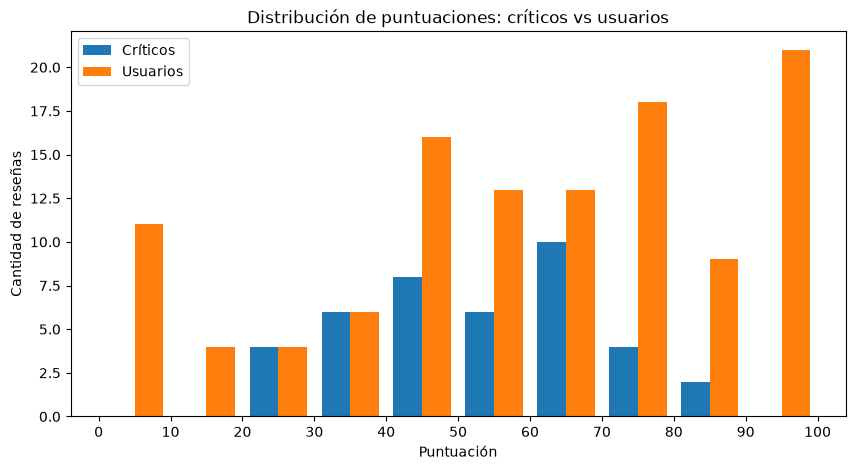

In [118]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5)) # Definimos el tamaño del grafico, por las dudas, los valores 10 y 5 representan pulgadas

#plt.hist crea un histograma, lo utilizamos para poder agrupar los valores numericos en intervalos y contar cuantos registros hay dentro de cada intervalo
plt.hist( 
    [   
        #aca comprobamos que filas corresponden a los criticos seleccionando unicamente la columna originalScore que es donde estan las puntuaciones

        df_limpio[df_limpio["reviewType"] == "critic"]["originalScore"], #Seleccionamos la puntuaciones de los criticos
        df_limpio[df_limpio["reviewType"] == "user"]["originalScore"] #Seleccionamos la puntuaciones de los usuarios

        #aca comprobamos que filas corresponden a los usuarios y tambien seleccionamos unicamente la columna originalScore que es donde estan las puntuaciones

    ],
    bins=10, #con bins, vamos a dividir el rango de puntuaciones en 10 intervalos
    label=["Críticos", "Usuarios"], #Asignamos los nombres que apareceran en el grafico
    alpha=1 #podemos controlar la transparencia de las barras en el grafico, para que sea mas o menos opacas
)

plt.xlabel("Puntuación") #Asignamos el nombre que va a tener de manera horizontal (eje X)
plt.ylabel("Cantidad de reseñas") #Asignamos el nombre que va a tener de manera vertical (eje Y)
plt.title("Distribución de puntuaciones: críticos vs usuarios") #Asignamos el titulo en el grafico
plt.legend() #Nos muestra la referencia de los colores para poder saber a que representa cada uno
plt.xticks(range(0, 101, 10))# Nos permite personalizar las marcas y los valores que aparecen en el eje(X) y utilizamos range() para definir su estructura (inicio, final, salto)
plt.show() #Muestra el grafico

El histograma nos muestra algunas diferencias en la distribucion de las puntuaciones entre los criticos y los usuarios.

Las calificaciones de los criticos se encuentran mas concentradas en los rangos intermedios, mientras que las de los usuarios presentan

Una mayor dispersion, donde hacen mas presencia de puntuaciones muy bajas y muy altas

Esto nos indica que la puntuacion del publico son mas variadas entre si

Ahora vamos a ver los sentimientos que tuvieron esos puntajes para que nos muestre cuantos son positivos y cuantos son negativos

utilizando groupby() para agrupar los registros segun las columnas
        *   reviewType separamos las reseñas entre critic y user
        *   sentiment separamos las reseñas entre POSITIVE, NEGATIVE, MIXED

Con size() contamos las filas que hay

Con .unstack() nos los muestra como una tabla

In [127]:
import pandas as pd

df_limpio.groupby(["reviewType", "sentiment"]).size().unstack()

sentiment,MIXED,NEGATIVE,POSITIVE
reviewType,,,
critic,20,10,10
user,42,24,49


Ahora vamos a mostrar esos mismos valores pero en porcentajes

Para ello vamos a crear una variable para la columna "sentiment" que contiene los valores de positivo, negativo, mixed

y otra variable para los porcentajes

In [129]:
tabla_sentimiento = (
    df_limpio.groupby(["reviewType", "sentiment"])
    .size()
    .unstack(fill_value=0)
)

tabla_porcentajes = tabla_sentimiento.div( #con .div indicamos que queremos dividir
    tabla_sentimiento.sum(axis=1), axis=0 #con (axis 1) vamos a indicarle que queremos sumar horizontalmente, con (axis 0) trabajamos de manera horizontal
).mul(100).round(2)

tabla_porcentajes

sentiment,MIXED,NEGATIVE,POSITIVE
reviewType,,,
critic,50.00,25.00,25.00
user,36.52,20.87,42.61



-   MIXED
        CRITICOS: 50%
        USUARIO: 36.52%
         
-   NEGATIVOS:
        CRITICOS: 25%
        USUARIO: 20.87%

-   POSITIVOS:
        CRITICOS: 25%
        USUARIOS: 42.61%


Se observa que el 42.61% de las reseñas de los usuarios fueron positivos frente a un 25% de las reseñas de los criticos

Mientras que tenemos un mayor puntaje negativo del 25% por parte de los criticos frente a los usuarios con un 20.87%

Y un 50% de las reseñas de los criticos fueron Mixed, mientras que entre los usuarios representa un 36.52%

Estos resultados muestran entre los usuarios una mayor proporcion de puntuaciones positivas y una menor proporcion de puntuaciones negativas que los criticos

Ahora voy a crear un grafico del mismo para que se pueda visualizar mucho mejor

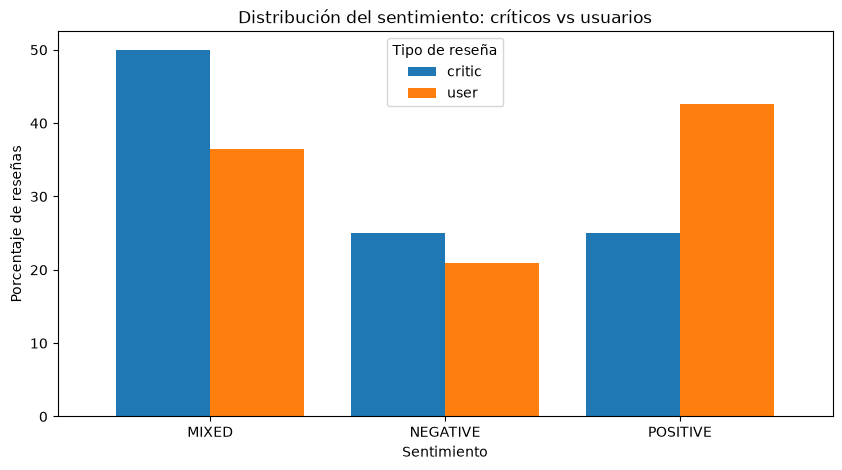

In [130]:
import matplotlib.pyplot as plt

tabla_porcentajes.T.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.8
)

plt.xlabel("Sentimiento")
plt.ylabel("Porcentaje de reseñas")
plt.title("Distribución del sentimiento: críticos vs usuarios")
plt.xticks(rotation=0)
plt.legend(title="Tipo de reseña")
plt.show()

Observamos que las reseñas de los criticos presentan una mayor proporcion de categorias MIXED(50%) y NEGATIVE(25%)

Mientras que las reseñas de los usuarios muestran una mayor proporcion de categoria POSITIVE (42.61%)

Ahora vamos a analizar los comentarios

In [5]:
import pandas as pd

df_limpio[["reviewType", "reviewText"]].head(10)

,reviewType,reviewText
0,critic,"Half the time, Black’s dialogue is just announ..."
1,critic,It feels like a small miracle that the resulti...
2,critic,"A relatively accessible, often enjoyable adapt..."
3,critic,"Perhaps there’s an alternative out there, a sh..."
4,critic,"A Minecraft Movie is not funny, exciting, or c..."
5,critic,"Jared Hess, co-creator of Napoleon Dynamite an..."
6,critic,There’s something almost refreshingly bold in ...
7,critic,Hess and his army of screenwriters (only five ...
8,critic,A video game movie that encourages creation in...
9,critic,The Jared Hess-directed action-adventure artfu...


Haremos un analisis del sentimiento textual y temas principales para que podamos luego ver que temas difieren uno de los otros

Para eso voy a crear 2 columnas nuevas, una la voy a llamar text_sentimient para que muestre el sentimiento expresado

 y el otro main_theme para que muestre el tema principal de la reseña

In [28]:
import pandas as pd

df_limpio["main_theme"].value_counts()

main_theme
Adaptación y referencias a Minecraft    48
Actuaciones y personajes                35
Guion e historia                        32
Humor y entretenimiento                 23
Aspectos audiovisuales                  10
Otros                                    7
Name: count, dtype: int64

In [29]:
tabla_temas = pd.crosstab(
    df_limpio["reviewType"],
    df_limpio["main_theme"]
)

tabla_temas

main_theme,Actuaciones y personajes,Adaptación y referencias a Minecraft,Aspectos audiovisuales,Guion e historia,Humor y entretenimiento,Otros
reviewType,,,,,,
critic,9,8,0,14,8,1
user,26,40,10,18,15,6


In [30]:
tabla_temas_porcentajes = (
    tabla_temas.div(tabla_temas.sum(axis=1), axis=0)
    .mul(100)
    .round(2)
)

tabla_temas_porcentajes

main_theme,Actuaciones y personajes,Adaptación y referencias a Minecraft,Aspectos audiovisuales,Guion e historia,Humor y entretenimiento,Otros
reviewType,,,,,,
critic,22.50,20.00,0.0,35.00,20.00,2.50
user,22.61,34.78,8.7,15.65,13.04,5.22


Aca podemos ver que encontramos que los criticos se enfocan mas en el guion y la historia

    Obteniendo un 35% de los criticos sobre un 15.65% de los usuarios, lo que nos da una diferencia de 19.35 puntos porcentuales


 Mientras que los usuarios destacan mas la adaptacion y referencias hacia Minecraft obteniendo un 34.78% sobre un 20% de los criticos
    
    Lo que nos da una diferencia de 14.78 puntos porcentuales

Las actuaciones y personajes de la pelicula, ambas reseñas estan balanceadas obteniento un 22.50% por parte de los criticos y un 22.61% por parte de los usuarios

Tambien hay una diferencia en como la pelicula impacto para los criticos y los publicos

    *   Los criticos parece que le prestan mas atencion a la narrativa y el desarrollo de la historia
    *   Para los usuarios parece que le dan mas importancia a la adaptacion del videojuego y las referencias con las que se pueden encontrar dentro de la pelicula

Ambos publicos priorizan aspectos diferentes para evaluar la pelicula



Creamos una variable para poder ver que puntuaciones recibe cada tema y como cambian entre criticos y usuarios

In [31]:
tabla_puntuaciones = (
    df_limpio.groupby(["reviewType", "main_theme"])["originalScore"]
    .agg(["count", "mean", "median"])
    .round(2)
)

tabla_puntuaciones

count   mean  median
reviewType main_theme                                                
critic     Actuaciones y personajes                  9  56.67    60.0
           Adaptación y referencias a Minecraft      8  49.50    47.5
           Guion e historia                         14  43.79    41.0
           Humor y entretenimiento                   8  53.25    60.0
           Otros                                     1  45.00    45.0
user       Actuaciones y personajes                 26  55.77    60.0
           Adaptación y referencias a Minecraft     40  61.00    60.0
           Aspectos audiovisuales                   10  53.00    50.0
           Guion e historia                         18  38.89    40.0
           Humor y entretenimiento                  15  70.67    70.0
           Otros                                     6  30.00    15.0

Resultado

    Criticos:
        *   Actuaciones y personajes tiene un promedio del 56.67 puntos con 9 reseñas
        *   Humor y entretenimiento tiene un promedio del 53.25 puntos con 8 reseñas
        *   Adaptacion a Minecraft tiene un promedio del 49.50 puntos con 8 reseñas
        *   Guion e historia tiene un promedio del 43.79 puntos con 14 reseñas

Los criticos valoran mejor las actuaciones mientras que el guion y la historia reciben puntuaciones mas baja

    Usuarios:
        *   Humor y entretenimiento tiene un promedio del 70.67 puntos con 15 reseñas
        *   Adaptacion a Minecraft tiene un promedio del 61 puntos con 40 reseñas
        *   Actuaciones y personajes tiene un promedio del 55.77 puntos con 26 reseñas
        *   Aspectos audiovisuales tiene un promedio del 53 puntos con 10 reseñas
        *   Guion e historia tiene un promedio del 38.89 puntos con 18 reseñas
        *   Otros tiene un promedio del 30 puntos con 6 reseñas

El publico valora mas el humor y las adaptaciones y referencias hacia Minecraft que el guion




Hallazgos encontrados

    1.  Los usuarios otorgan al humor un promedio de 70.67 puntos frente a 53.25 de los criticos. Por lo que tenemos una recepcion

        Mas favorable de los elementos comicos entre el publico
    
    2.  El guion y la historia presentan puntuaciones promedio bajas tanto entre los criticos con un 43.79 puntos como entre los usuarios con 38.39 puntos. Por lo que

        las debilidades que tiene la narrativa son un punto de coincidencia entre ambos grupos

In [32]:
promedios_temas = (
    tabla_puntuaciones["mean"]
    .unstack(level="reviewType")
)

promedios_temas

reviewType,critic,user
main_theme,,
Actuaciones y personajes,56.67,55.77
Adaptación y referencias a Minecraft,49.50,61.00
Aspectos audiovisuales,NaN,53.00
Guion e historia,43.79,38.89
Humor y entretenimiento,53.25,70.67
Otros,45.00,30.00


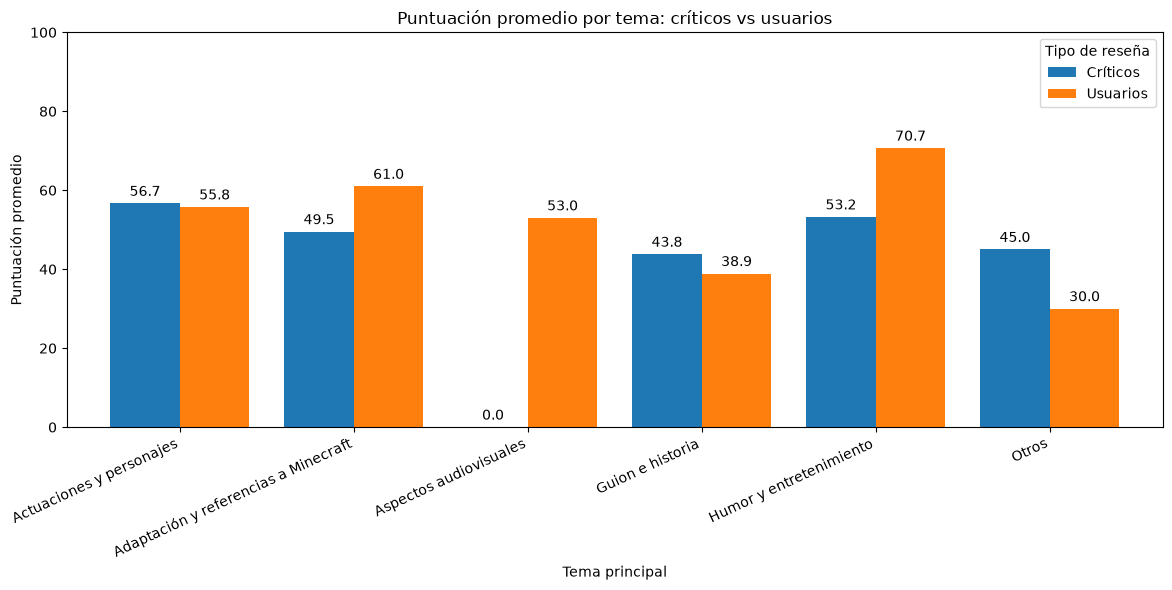

In [36]:
import matplotlib.pyplot as plt

ax = promedios_temas.rename(
    columns={"critic": "Críticos", "user": "Usuarios"}
).plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.xlabel("Tema principal")
plt.ylabel("Puntuación promedio")
plt.title("Puntuación promedio por tema: críticos vs usuarios")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 100)
plt.legend(title="Tipo de reseña")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)

plt.tight_layout()
plt.show()

Podemos observar las siguientes cosas:

    *   Los usuarios tiene un promedio del 70.7 frente a 53.2 de los criticos en el humor y entretenimiento, es la mayor diferencia a favor del publico
    *   Los usuarios tienen un promedio de 61 puntos, mientras que los criticos tienen un 49.5 respecto a la adaptacion y referencias sobre Minecraft
    *   En el guion e historia, ambos grupos tienen una puntuacion baja, los usuarios tienen 38.9 y los criticos 43.8
    *   En las actuaciones y personajes casi no hay diferencia, tenemos 56.7 en los criticos y 55.8 para los usuarios

Ahora procedo a guardar la base de datos con la limpieza en la carpeta processed

In [37]:
import pandas as pd

df_limpio.to_csv(
    "../data/processed/reviews_limpia.csv",
    index=False,
    encoding="utf-8"
)

## 5. Hallazgos principales

A partir del análisis que hice, se identificaron tres diferencias relevantes en la recepción de *A Minecraft Movie* entre críticos y usuarios.

### Diferencias en la valoración del humor

**Hallazgo:** Las reseñas cuyo tema principal fue el humor y entretenimiento presentan una puntuación promedio de 70,67 puntos entre los usuarios, frente a 53,25 puntos entre los críticos. Esto representa una diferencia de 17,42 puntos.

**Importancia:** Este resultado sugiere que los elementos cómicos de la película tuvieron una recepción más favorable entre los usuarios que entre los críticos.

**Explicación alternativa considerada:** La diferencia podría deberse a la cantidad desigual de reseñas o a las distintas expectativas de ambos grupos. Al comparar porcentajes de temas y promedios dentro de cada grupo, se reduce el efecto de los tamaños de muestra diferentes.

### Coincidencia en la valoración del guion y la historia

**Hallazgo:** El guion y la historia presentan puntuaciones promedio de 43,79 puntos entre los críticos y 38,89 puntos entre los usuarios.

**Importancia:** Ambos grupos muestran una valoración relativamente baja de este aspecto, lo que representa un punto de coincidencia entre la crítica especializada y la audiencia.

**Explicación alternativa considerada:** La diferencia podría estar influida por la cantidad y selección de reseñas incluidas en cada grupo. Sin embargo, ambos grupos presentan promedios bajos en esta categoría. Esto respalda la existencia de una coincidencia descriptiva, aunque no permite generalizarla a todos los espectadores.

### Diferencias en la atención a la adaptación de Minecraft

**Hallazgo:** La adaptación y las referencias a Minecraft representan el 20% de los temas principales de las reseñas de críticos y el 34,78% de las de usuarios. Sus puntuaciones promedio son de 49,50 y 61 puntos, respectivamente.

**Importancia:** Los usuarios mencionan con mayor frecuencia la adaptación al videojuego y también presentan una valoración promedio superior en las reseñas agrupadas bajo este tema.

**Explicación alternativa considerada:** La diferencia podría estar relacionada con la familiaridad de los espectadores con el videojuego. 

## 6. Conclusiones y recomendaciones

### Conclusiones

El análisis de las 155 reseñas de *A Minecraft Movie* permitió identificar diferencias y coincidencias entre la recepción de los críticos especializados y los usuarios.

Los resultados muestran que los usuarios presentan una valoración más favorable del humor y de los elementos vinculados con la adaptación al videojuego. En cambio, los críticos concentran una mayor proporción de sus reseñas en el guion y la historia.

A pesar de estas diferencias, ambos grupos coinciden en presentar puntuaciones relativamente bajas en las reseñas cuyo tema principal es el guion y la historia.

En conjunto, los resultados sugieren que la recepción de la película varía según los aspectos que destacan los distintos grupos de evaluadores.

### Recomendaciones

A partir de los resultados obtenidos, se proponen las siguientes recomendaciones:

1. **Priorizar el análisis de la audiencia:** considerar las referencias al videojuego y los elementos cómicos como aspectos relevantes para comprender la conexión de una película con su público.

2. **Prestar atención a la calidad narrativa:** los resultados muestran puntuaciones relativamente bajas en el tema guion e historia tanto entre críticos como entre usuarios. Es un aspecto que merece atención en futuras producciones.

3. **Analizar por separado la recepción crítica y la del público:** Se recomienda analizar por separado las calificaciones y los temas destacados por críticos y usuarios, ya que ambos grupos pueden tener perspectivas diferentes sobre la pelicula.

###  Alcance de las conclusiones

Los resultados corresponden a las 155 reseñas recopiladas manualmente y analizadas. No representan necesariamente a la totalidad de los críticos ni de los espectadores de la película.
